# Классификация астрофизических источников (3FGL)

Блазары (1) и пульсары (-1). В исходном каталоге 3034 объекта,
после отбора этих классов остаётся 1884: 1717 блазаров и 167 пульсаров.

Сначала отделяем test, затем выделяем validation из оставшихся данных.
PCA, масштабирование и важности признаков обучаем только на train.
Число компонент, число признаков и итоговый вариант выбираем по F1 пульсаров
на validation. Test используем в последнем блоке, когда выбор уже сделан.


In [1]:
import numpy as np
import random
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, balanced_accuracy_score)
from matplotlib import pyplot as plt
import seaborn as sns


In [3]:
from pathlib import Path
from urllib.request import urlretrieve
if not Path('3fgl_full.dat').exists():
    urlretrieve('ftp://cluster.inr.ac.ru/pub/ML/3FGL/3fgl_full.dat', '3fgl_full.dat')


In [4]:
data = np.loadtxt("3fgl_full.dat", dtype=str)
columns = ['Name','RA','Dec'] + ['Par' + str(i) for i in range(1,27)] + ['SourceType']
df = pd.DataFrame(data=data, columns=columns)
df


,Name,RA,Dec,Par1,Par2,Par3,Par4,Par5,Par6,Par7,...,Par18,Par19,Par20,Par21,Par22,Par23,Par24,Par25,Par26,SourceType
0,J0000.1+6545,0.0377,65.7517,0.0628,0.0481,41.030,6.813,1159.08,1.0053E-12,1.0160E-09,...,2.855343E-12,6.022,5.780520E-11,3.784131E-13,1.509,2.839629E-11,4.317204E-13,2.421,4.075352E+01,NULL
1,J0000.2-3738,0.0612,-37.6484,0.0451,0.0417,-88.550,5.091,3296.33,1.9420E-14,2.0387E-10,...,3.532782E-13,2.941,7.452389E-11,5.197980E-13,4.154,1.590734E-11,2.991650E-13,3.469,4.484532E+01,NULL
2,J0001.0+6314,0.2535,63.2440,0.1526,0.0986,-65.320,6.164,472.16,8.6247E-12,6.4037E-10,...,6.768034E-13,1.748,1.158661E-10,7.319140E-13,3.275,2.021964E-12,2.761839E-14,0.362,5.304786E+01,spp
3,J0001.2-0748,0.3209,-7.8159,0.0503,0.0429,-19.470,11.253,1263.84,4.8539E-13,6.9522E-10,...,1.236880E-12,6.997,2.106892E-10,1.421389E-12,8.018,1.005633E-11,1.686281E-13,1.574,4.973821E+01,bll
4,J0001.4+2120,0.3612,21.3379,0.1298,0.1162,-32.550,11.350,310.68,2.5221E-11,2.9449E-10,...,7.152622E-13,4.517,8.413887E-15,4.392482E-17,0.000,1.035538E-14,9.594525E-17,0.000,1.303363E+02,fsrq
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3029,J2358.5+3827,359.6342,38.4539,0.0622,0.0461,79.940,5.892,2814.47,4.8144E-14,3.8089E-10,...,7.105315E-13,3.873,7.908256E-11,5.380139E-13,4.051,3.489049E-11,6.018759E-13,3.435,5.231089E+01,NULL
3030,J2358.6-1809,359.6659,-18.1585,0.0445,0.0394,19.880,6.513,3925.48,2.1028E-14,3.0164E-10,...,4.460927E-13,3.343,1.212272E-10,8.506079E-13,5.529,3.124023E-11,6.000252E-13,4.136,4.880265E+01,NULL
3031,J2358.9+3926,359.7360,39.4476,0.1079,0.0879,10.360,4.685,2167.58,7.4583E-14,3.3950E-10,...,7.315058E-13,3.687,2.752512E-12,1.844227E-14,0.145,4.889366E-11,8.012898E-13,4.207,5.285284E+01,fsrq
3032,J2359.3-3038,359.8291,-30.6465,0.0335,0.0314,-6.680,11.055,2239.89,1.1999E-13,5.9432E-10,...,1.048397E-12,6.609,1.267952E-10,8.683160E-13,6.162,5.573432E-11,9.833648E-13,6.002,4.096702E+01,bll


In [5]:
print(df.columns)


Index(['Name', 'RA', 'Dec', 'Par1', 'Par2', 'Par3', 'Par4', 'Par5', 'Par6',
       'Par7', 'Par8', 'Par9', 'Par10', 'Par11', 'Par12', 'Par13', 'Par14',
       'Par15', 'Par16', 'Par17', 'Par18', 'Par19', 'Par20', 'Par21', 'Par22',
       'Par23', 'Par24', 'Par25', 'Par26', 'SourceType'],
      dtype='object')


In [6]:
df["RA"] = pd.to_numeric(df["RA"])
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3034 entries, 0 to 3033
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        3034 non-null   object 
 1   RA          3034 non-null   float64
 2   Dec         3034 non-null   object 
 3   Par1        3034 non-null   object 
 4   Par2        3034 non-null   object 
 5   Par3        3034 non-null   object 
 6   Par4        3034 non-null   object 
 7   Par5        3034 non-null   object 
 8   Par6        3034 non-null   object 
 9   Par7        3034 non-null   object 
 10  Par8        3034 non-null   object 
 11  Par9        3034 non-null   object 
 12  Par10       3034 non-null   object 
 13  Par11       3034 non-null   object 
 14  Par12       3034 non-null   object 
 15  Par13       3034 non-null   object 
 16  Par14       3034 non-null   object 
 17  Par15       3034 non-null   object 
 18  Par16       3034 non-null   object 
 19  Par17       3034 non-null  

In [7]:
df.describe()


,RA
count,3034.000000
mean,185.637860
std,100.601810
min,0.037700
25%,102.768650
50%,189.986000
75%,270.376075
max,359.881200


In [10]:
# преобразование типов нескольких колонок сразу
columns_to_convert = columns[1:-1]  # пропускаем нулевой и последний столбцы
df[columns_to_convert] = df[columns_to_convert].apply(pd.to_numeric)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3034 entries, 0 to 3033
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        3034 non-null   object 
 1   RA          3034 non-null   float64
 2   Dec         3034 non-null   float64
 3   Par1        3034 non-null   float64
 4   Par2        3034 non-null   float64
 5   Par3        3034 non-null   float64
 6   Par4        3034 non-null   float64
 7   Par5        3034 non-null   float64
 8   Par6        3034 non-null   float64
 9   Par7        3034 non-null   float64
 10  Par8        3034 non-null   float64
 11  Par9        3034 non-null   float64
 12  Par10       3034 non-null   float64
 13  Par11       3034 non-null   float64
 14  Par12       3034 non-null   float64
 15  Par13       3034 non-null   float64
 16  Par14       3034 non-null   float64
 17  Par15       3034 non-null   float64
 18  Par16       3034 non-null   float64
 19  Par17       3034 non-null  

In [11]:
df[df['SourceType']=='BCU']   # отсортировали чтобы были только BCU


,Name,RA,Dec,Par1,Par2,Par3,Par4,Par5,Par6,Par7,...,Par18,Par19,Par20,Par21,Par22,Par23,Par24,Par25,Par26,SourceType
248,J0210.7-5101,32.6972,-51.0282,0.0146,0.0139,41.61,62.948,385.06,5.930000e-11,4.740300e-09,...,9.830757e-12,38.016,7.063219e-10,4.505460e-12,20.693,9.707362e-11,1.242472e-12,8.745,1444.2840,BCU
590,J0522.9-3628,80.7416,-36.4715,0.0155,0.0144,-8.28,70.430,321.47,1.147900e-10,4.734500e-09,...,8.719110e-12,31.890,6.148073e-10,3.894717e-12,17.423,1.347864e-10,1.736439e-12,9.449,678.8578,BCU
611,J0532.0-4827,83.0004,-48.4585,0.0098,0.0097,62.92,73.833,791.89,1.581500e-11,8.362200e-09,...,1.456135e-11,45.883,1.842543e-09,1.221982e-11,37.134,3.559431e-10,5.178085e-12,17.354,2337.9320,BCU
706,J0622.9+3326,95.7346,33.4357,0.0116,0.0107,-70.21,56.144,507.63,3.725400e-11,7.030400e-09,...,1.232083e-11,30.588,1.466814e-09,9.670423e-12,26.820,3.120905e-10,4.543344e-12,15.229,3202.1380,BCU
1736,J1418.5+3543,214.6499,35.7186,0.0169,0.0152,-22.59,36.318,1220.98,1.775700e-12,2.511600e-09,...,4.313878e-12,21.388,6.632234e-10,4.522228e-12,20.912,1.315367e-10,2.286590e-12,9.893,905.9413,BCU


**ОБРАБОТКА**


In [12]:
df['SourceType'] = df['SourceType'].str.lower()   # в нижний регистр названия
print(df['SourceType'].value_counts(), '\n')


SourceType
null     1010
bll       660
bcu       573
fsrq      484
psr       167
spp        49
snr        23
glc        15
rdg        15
pwn        12
nlsy1       5
sbg         4
gal         3
hmb         3
ssrq        3
agn         3
bin         1
css         1
sey         1
sfr         1
nov         1
Name: count, dtype: int64 



**ОСТАВИМ ТОЛЬКО ПУЛЬСАРЫ И БЛАЗАРЫ**


In [13]:
blazars = ['bll', 'bcu', 'fsrq']
pulsars = ['psr']

clean = df['SourceType'].isin(blazars + pulsars)
df_clean = df[clean].copy()
print('SourceType в почищенном df:', df_clean['SourceType'].unique())
print('Размеры датафрейма:', df_clean.shape)


SourceType в почищенном df: ['bll' 'fsrq' 'bcu' 'psr']
Размеры датафрейма: (1884, 30)


In [14]:
def categorize_source(source_type):
  source_type = source_type.lower()
  if source_type in ['bll', 'bcu', 'fsrq']:   #блазары 1
    return 1
  else:
    return -1


df_clean['target'] = df_clean['SourceType'].apply(categorize_source)




print(df_clean['target'].value_counts())
df_clean.head()


target
 1    1717
-1     167
Name: count, dtype: int64


,Name,RA,Dec,Par1,Par2,Par3,Par4,Par5,Par6,Par7,...,Par19,Par20,Par21,Par22,Par23,Par24,Par25,Par26,SourceType,target
3,J0001.2-0748,0.3209,-7.8159,0.0503,0.0429,-19.47,11.253,1263.84,4.853900e-13,6.952200e-10,...,6.997,2.106892e-10,1.421389e-12,8.018,1.005633e-11,1.686281e-13,1.574,49.73821,bll,1
4,J0001.4+2120,0.3612,21.3379,0.1298,0.1162,-32.55,11.350,310.68,2.522100e-11,2.944900e-10,...,4.517,8.413887e-15,4.392482e-17,0.000,1.035538e-14,9.594525e-17,0.000,130.33630,fsrq,1
7,J0002.2-4152,0.5621,-41.8828,0.1337,0.0860,68.13,5.158,1956.04,7.324000e-14,2.714000e-10,...,1.513,9.763049e-11,6.633214e-13,4.735,2.590360e-11,4.448439e-13,2.584,56.35106,bcu,1
9,J0003.2-5246,0.8152,-52.7771,0.0430,0.0377,-44.41,5.670,3676.23,1.998800e-14,2.590400e-10,...,3.079,7.936658e-11,5.517048e-13,3.738,2.977405e-11,5.533345e-13,4.510,45.28044,bcu,1
12,J0003.8-1151,0.9588,-11.8627,0.0801,0.0618,-16.73,4.181,2315.88,4.415200e-14,2.339000e-10,...,3.793,4.661099e-11,3.191276e-13,2.465,1.772286e-11,3.124540e-13,2.541,48.49165,bcu,1


In [19]:
feature_columns = [col for col in df_clean.columns if col not in ['Name', 'SourceType', 'target']]
print('Признаков для анализа:', len(feature_columns))

X = df_clean[feature_columns]
y = df_clean['target']
print('Исходно:', X.shape)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.3, random_state=67, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=67, stratify=y_train_val) # валидация на 20% от 70% = 14% данных; train -- 56%

print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Классы в train:', y_train.value_counts().to_dict())
print('Классы в validation:', y_val.value_counts().to_dict())


Признаков для анализа: 28
Исходно: (1884, 28)
Train: (1054, 28) Validation: (264, 28) Test: (566, 28)
Классы в train: {1: 960, -1: 94}
Классы в validation: {1: 241, -1: 23}


**ДЕЛАЕМ МАТРИЦУ КОВАРИАЦИЙ ДИАГОНАЛЬНОЙ**

Масштабы признаков сильно различаются, поэтому перед PCA используем StandardScaler.
Для heatmap сохраняем знак ковариации: обычный log(1 + C) не определён при C < -1.
Дерево на исходных признаках ниже обучается без масштабирования.


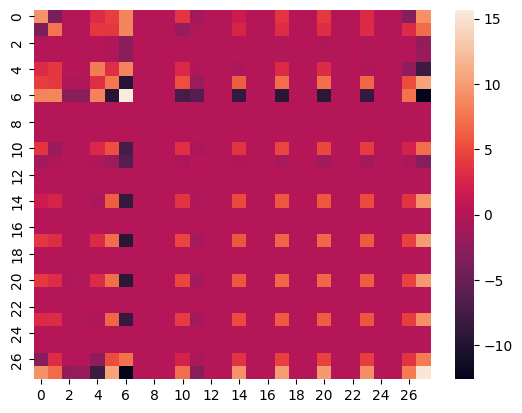

In [20]:
C=np.cov(np.transpose(X_train))
sns.heatmap(np.sign(C) * np.log1p(np.abs(C)));
plt.show()


(1054, 28)
(28, 28)


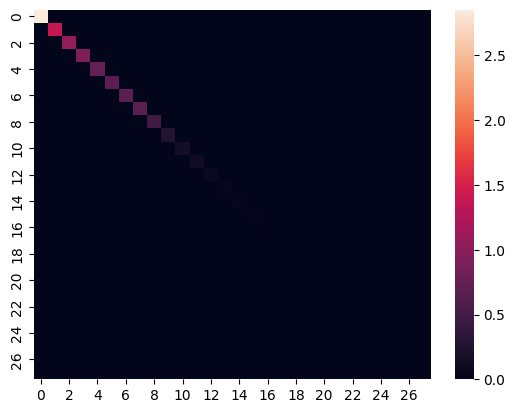

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

pca = PCA() # по умолчанию сохраняем все компоненты
XPCAreduced_train = pca.fit_transform(X_train_scaled)
XPCAreduced_val = pca.transform(X_val_scaled)

print(XPCAreduced_train.shape)
C=np.cov(np.transpose(XPCAreduced_train))
print(C.shape)
sns.heatmap(np.sign(C) * np.log1p(np.abs(C)));
plt.show()


In [22]:
for i in range (len(C)):
  print(f'{i}, {C[i,i]:.4f}') # дисперсия по компонентам


0, 16.3519
1, 2.9531
2, 1.8809
3, 1.4320
4, 1.1194
5, 0.9750
6, 0.9646
7, 0.9593
8, 0.5997
9, 0.2939
10, 0.1540
11, 0.1278
12, 0.0773
13, 0.0444
14, 0.0418
15, 0.0246
16, 0.0115
17, 0.0084
18, 0.0041
19, 0.0021
20, 0.0004
21, 0.0003
22, 0.0001
23, 0.0000
24, 0.0000
25, 0.0000
26, 0.0000
27, 0.0000


**ОБУЧИМ МОДЕЛЬ НА ПРЕОБРАЗОВАННЫХ ДАННЫХ**


28
(1054, 28)
Компонент использовано: 28, Accuracy на train: 0.9696
Компонент использовано: 27, Accuracy на train: 0.9668
Компонент использовано: 26, Accuracy на train: 0.9668
Компонент использовано: 25, Accuracy на train: 0.9668
Компонент использовано: 24, Accuracy на train: 0.9668
Компонент использовано: 23, Accuracy на train: 0.9668
Компонент использовано: 22, Accuracy на train: 0.9668
Компонент использовано: 21, Accuracy на train: 0.9658
Компонент использовано: 20, Accuracy на train: 0.9658
Компонент использовано: 19, Accuracy на train: 0.9658
Компонент использовано: 18, Accuracy на train: 0.9658
Компонент использовано: 17, Accuracy на train: 0.9658
Компонент использовано: 16, Accuracy на train: 0.9658
Компонент использовано: 15, Accuracy на train: 0.9658
Компонент использовано: 14, Accuracy на train: 0.9658
Компонент использовано: 13, Accuracy на train: 0.9668
Компонент использовано: 12, Accuracy на train: 0.9668
Компонент использовано: 11, Accuracy на train: 0.9668
Компонент испо

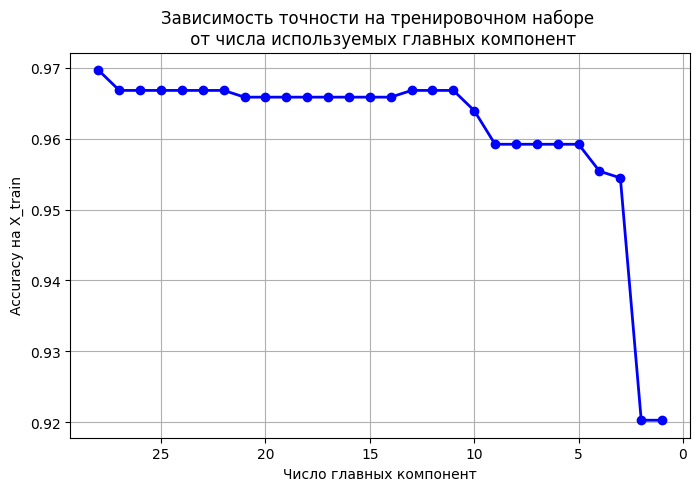

In [23]:
num_components = len(feature_columns)
print(num_components)
print(XPCAreduced_train.shape)



accuracies_train = []
num_features_used = []

for n in range(num_components, 0, -1):   # берем компоненты начиная с 28 и до 1 с шагом -1
  X_train_subset = XPCAreduced_train[:, :n]  # остались все строки n столбцов

  tree = DecisionTreeClassifier(criterion='gini', max_depth=4,random_state=42)
  tree.fit(X_train_subset, y_train)

  accuracy_train = tree.score(X_train_subset, y_train)
  accuracies_train.append(accuracy_train)
  num_features_used.append(n)

  print(f"Компонент использовано: {n}, Accuracy на train: {accuracy_train:.4f}")
plt.figure(figsize=(8, 5))
plt.plot(num_features_used, accuracies_train, 'bo-', linewidth=2, markersize=6)
plt.title('Зависимость точности на тренировочном наборе \n от числа используемых главных компонент')
plt.xlabel('Число главных компонент')
plt.ylabel('Accuracy на X_train')
plt.grid(True)
plt.gca().invert_xaxis()
plt.show()


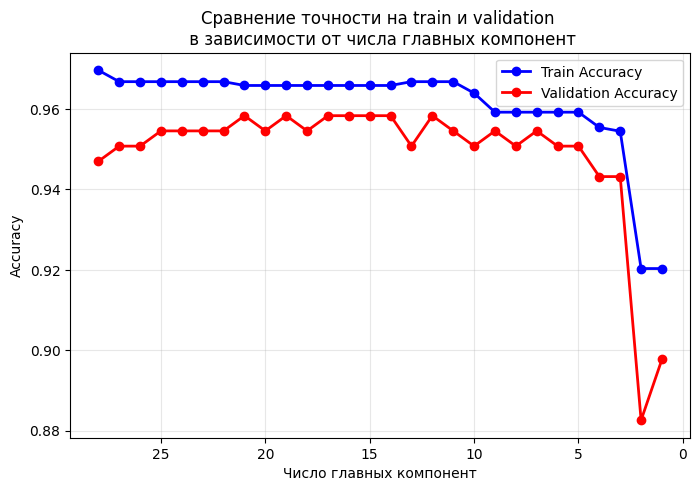

Лучшее число компонент: 12
F1 пульсаров на validation: 0.7027
Accuracy на validation: 0.9583


In [24]:
num_components = len(feature_columns)
accuracies_train = []
accuracies_val = []
f1_val = []
num_features_used = []

for n in range(num_components, 0, -1):
  X_train_subset = XPCAreduced_train[:, :n]
  X_val_subset = XPCAreduced_val[:, :n]

  tree = DecisionTreeClassifier(max_depth=4, random_state=42)
  tree.fit(X_train_subset, y_train)
  y_pred_val = tree.predict(X_val_subset)

  accuracies_train.append(tree.score(X_train_subset, y_train))
  accuracies_val.append(accuracy_score(y_val, y_pred_val))
  f1_val.append(f1_score(y_val, y_pred_val, pos_label=-1, zero_division=0))
  num_features_used.append(n)

plt.figure(figsize=(8, 5))
plt.plot(num_features_used, accuracies_train, 'bo-', linewidth=2, markersize=6, label='Train Accuracy')
plt.plot(num_features_used, accuracies_val, 'ro-', linewidth=2, markersize=6, label='Validation Accuracy')
plt.title('Сравнение точности на train и validation \n в зависимости от числа главных компонент')
plt.xlabel('Число главных компонент')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)
plt.gca().invert_xaxis()
plt.legend()
plt.show()

# При равном F1 оставляем меньше компонент
best_index = len(f1_val) - 1 - np.argmax(f1_val[::-1])
best_n = num_features_used[best_index]
print('Лучшее число компонент:', best_n)
print(f'F1 пульсаров на validation: {f1_val[best_index]:.4f}')
print(f'Accuracy на validation: {accuracies_val[best_index]:.4f}')


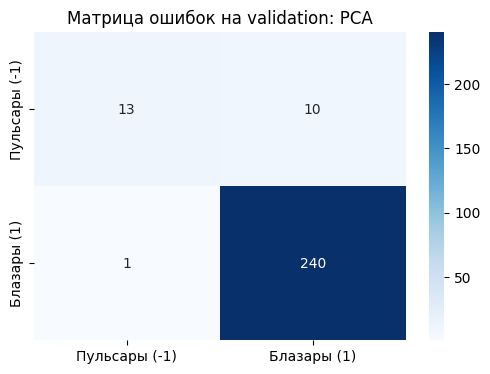

              precision    recall  f1-score   support

    Пульсары       0.93      0.57      0.70        23
     Блазары       0.96      1.00      0.98       241

    accuracy                           0.96       264
   macro avg       0.94      0.78      0.84       264
weighted avg       0.96      0.96      0.95       264



In [26]:
tree_pca = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_pca.fit(XPCAreduced_train[:, :best_n], y_train)
y_pred_val_pca = tree_pca.predict(XPCAreduced_val[:, :best_n])

cm = confusion_matrix(y_val, y_pred_val_pca, labels=[-1, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Пульсары (-1)', 'Блазары (1)'], yticklabels=['Пульсары (-1)', 'Блазары (1)'])
plt.title('Матрица ошибок на validation: PCA')
plt.show()
print(classification_report(y_val, y_pred_val_pca, labels=[-1, 1], target_names=['Пульсары', 'Блазары'], zero_division=0))


РАЗМНОЖИМ ***ДАННЫЕ***

Добавляем четыре копии пульсаров только к train. Число компонент оставляем тем же,
что в предыдущем варианте. Validation и test сохраняют исходное распределение классов.


In [27]:
train_data = pd.concat([X_train, y_train], axis=1)
pulsars_train = train_data[train_data['target'] == -1]
train_balanced = pd.concat([train_data, pulsars_train, pulsars_train, pulsars_train, pulsars_train])
train_balanced = train_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
print(train_balanced['target'].value_counts())


target
 1    960
-1    470
Name: count, dtype: int64


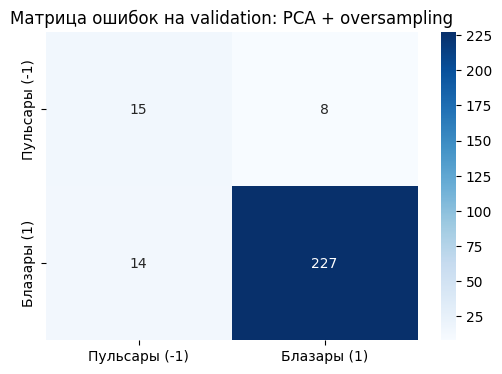

              precision    recall  f1-score   support

    Пульсары       0.52      0.65      0.58        23
     Блазары       0.97      0.94      0.95       241

    accuracy                           0.92       264
   macro avg       0.74      0.80      0.77       264
weighted avg       0.93      0.92      0.92       264



In [28]:
X_train_bal = train_balanced[feature_columns]
y_train_bal = train_balanced['target']

scaler_aug = StandardScaler()
X_train_bal_scaled = scaler_aug.fit_transform(X_train_bal)
X_val_aug_scaled = scaler_aug.transform(X_val)

pca_aug = PCA()
XPCAreduced_train_aug = pca_aug.fit_transform(X_train_bal_scaled)
XPCAreduced_val_aug = pca_aug.transform(X_val_aug_scaled)

tree_aug = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_aug.fit(XPCAreduced_train_aug[:, :best_n], y_train_bal)
y_pred_val_aug = tree_aug.predict(XPCAreduced_val_aug[:, :best_n])

cm = confusion_matrix(y_val, y_pred_val_aug, labels=[-1, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Пульсары (-1)', 'Блазары (1)'], yticklabels=['Пульсары (-1)', 'Блазары (1)'])
plt.title('Матрица ошибок на validation: PCA + oversampling')
plt.show()
print(classification_report(y_val, y_pred_val_aug, labels=[-1, 1],
                            target_names=['Пульсары', 'Блазары'], zero_division=0))


***Обучимся используя feature_importances***


In [29]:
df_clean


,Name,RA,Dec,Par1,Par2,Par3,Par4,Par5,Par6,Par7,...,Par19,Par20,Par21,Par22,Par23,Par24,Par25,Par26,SourceType,target
3,J0001.2-0748,0.3209,-7.8159,0.0503,0.0429,-19.47,11.253,1263.84,4.853900e-13,6.952200e-10,...,6.997,2.106892e-10,1.421389e-12,8.018,1.005633e-11,1.686281e-13,1.574,49.73821,bll,1
4,J0001.4+2120,0.3612,21.3379,0.1298,0.1162,-32.55,11.350,310.68,2.522100e-11,2.944900e-10,...,4.517,8.413887e-15,4.392482e-17,0.000,1.035538e-14,9.594525e-17,0.000,130.33630,fsrq,1
7,J0002.2-4152,0.5621,-41.8828,0.1337,0.0860,68.13,5.158,1956.04,7.324000e-14,2.714000e-10,...,1.513,9.763049e-11,6.633214e-13,4.735,2.590360e-11,4.448439e-13,2.584,56.35106,bcu,1
9,J0003.2-5246,0.8152,-52.7771,0.0430,0.0377,-44.41,5.670,3676.23,1.998800e-14,2.590400e-10,...,3.079,7.936658e-11,5.517048e-13,3.738,2.977405e-11,5.533345e-13,4.510,45.28044,bcu,1
12,J0003.8-1151,0.9588,-11.8627,0.0801,0.0618,-16.73,4.181,2315.88,4.415200e-14,2.339000e-10,...,3.793,4.661099e-11,3.191276e-13,2.465,1.772286e-11,3.124540e-13,2.541,48.49165,bcu,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3027,J2358.2-1022,359.5502,-10.3699,0.1558,0.1312,58.86,6.358,368.79,6.646600e-12,2.274900e-10,...,2.343,6.816563e-13,4.276634e-15,0.000,4.451705e-12,5.964652e-14,0.488,68.61301,fsrq,1
3028,J2358.3-2853,359.5980,-28.8910,0.0764,0.0673,-39.28,6.234,970.00,4.395500e-13,2.884900e-10,...,2.351,8.747450e-11,5.724407e-13,5.046,2.301750e-15,3.495638e-17,0.000,45.93385,bcu,1
3031,J2358.9+3926,359.7360,39.4476,0.1079,0.0879,10.36,4.685,2167.58,7.458300e-14,3.395000e-10,...,3.687,2.752512e-12,1.844227e-14,0.145,4.889366e-11,8.012898e-13,4.207,52.85284,fsrq,1
3032,J2359.3-3038,359.8291,-30.6465,0.0335,0.0314,-6.68,11.055,2239.89,1.199900e-13,5.943200e-10,...,6.609,1.267952e-10,8.683160e-13,6.162,5.573432e-11,9.833648e-13,6.002,40.96702,bll,1


Важность исходных признаков по DecisionTree:
   feature  importance
10    Par9    0.599026
27   Par26    0.210743
7     Par6    0.058851
22   Par21    0.043097
23   Par22    0.025883
25   Par24    0.015102
1      Dec    0.013754
15   Par14    0.013346
6     Par5    0.013239
26   Par25    0.005094
4     Par3    0.001865
3     Par2    0.000000
11   Par10    0.000000
9     Par8    0.000000
8     Par7    0.000000
5     Par4    0.000000
2     Par1    0.000000
0       RA    0.000000
13   Par12    0.000000
12   Par11    0.000000
19   Par18    0.000000
18   Par17    0.000000
17   Par16    0.000000
16   Par15    0.000000
14   Par13    0.000000
21   Par20    0.000000
20   Par19    0.000000
24   Par23    0.000000


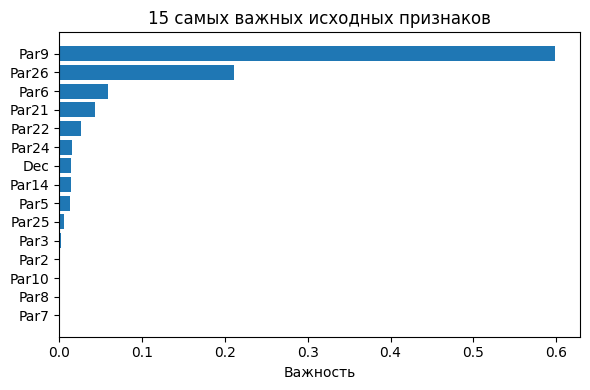

1.0
11


In [30]:
tree_original = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_original.fit(X_train, y_train)

importances = tree_original.feature_importances_

feature_importance_df = pd.DataFrame({'feature': feature_columns, 'importance': importances}).sort_values('importance', ascending=False)

print("Важность исходных признаков по DecisionTree:")
print(feature_importance_df)

# 15 самых важных признаков
plt.figure(figsize=(6, 4))
plt.barh(feature_importance_df['feature'][:15][::-1], feature_importance_df['importance'][:15][::-1])
plt.title('15 самых важных исходных признаков')
plt.xlabel('Важность')
plt.tight_layout()
plt.show()

# Суммарная важность
print(importances.sum())
print((importances > 0).sum())


Признаков: 28 | Train: 0.9772 | Validation: 0.9621
Признаков: 27 | Train: 0.9772 | Validation: 0.9621
Признаков: 26 | Train: 0.9772 | Validation: 0.9621
Признаков: 25 | Train: 0.9772 | Validation: 0.9583
Признаков: 24 | Train: 0.9772 | Validation: 0.9621
Признаков: 23 | Train: 0.9772 | Validation: 0.9583
Признаков: 22 | Train: 0.9772 | Validation: 0.9583
Признаков: 21 | Train: 0.9772 | Validation: 0.9583
Признаков: 20 | Train: 0.9772 | Validation: 0.9583
Признаков: 19 | Train: 0.9772 | Validation: 0.9583
Признаков: 18 | Train: 0.9772 | Validation: 0.9583
Признаков: 17 | Train: 0.9772 | Validation: 0.9583
Признаков: 16 | Train: 0.9772 | Validation: 0.9583
Признаков: 15 | Train: 0.9772 | Validation: 0.9583
Признаков: 14 | Train: 0.9772 | Validation: 0.9583
Признаков: 13 | Train: 0.9772 | Validation: 0.9583
Признаков: 12 | Train: 0.9772 | Validation: 0.9583
Признаков: 11 | Train: 0.9772 | Validation: 0.9583
Признаков: 10 | Train: 0.9772 | Validation: 0.9583
Признаков: 9 | Train: 0.9772 | 

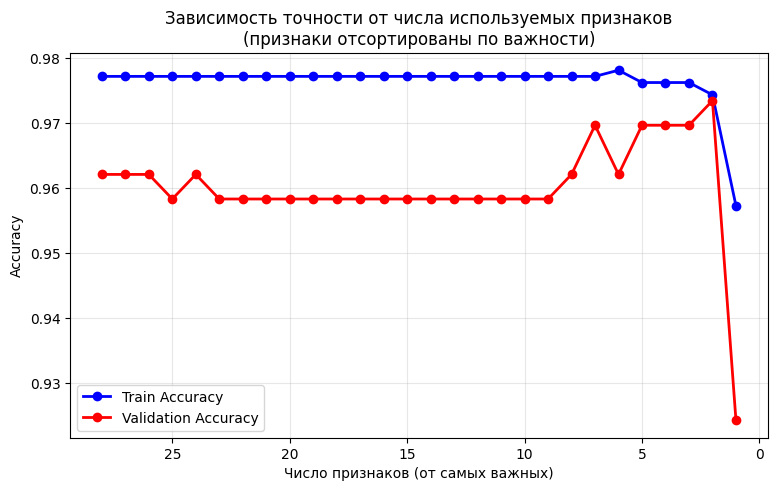

Выбрано признаков: 2
Признаки: ['Par26', 'Par9']
F1 пульсаров на validation: 0.8372


In [31]:
# сортируем признаки по важности, полученной только на train
sorted_features = feature_importance_df.sort_values('importance', ascending=True)['feature'].values
accuracies_train = []
accuracies_val = []
f1_val_features = []
num_features_used = []

for n in range(len(sorted_features), 0, -1):
  features_to_use = sorted_features[-n:]
  X_train_sub = X_train[features_to_use]
  X_val_sub = X_val[features_to_use]

  tree = DecisionTreeClassifier(max_depth=4, random_state=42)
  tree.fit(X_train_sub, y_train)
  y_pred_val = tree.predict(X_val_sub)

  acc_train = tree.score(X_train_sub, y_train)
  acc_val = accuracy_score(y_val, y_pred_val)
  accuracies_train.append(acc_train)
  accuracies_val.append(acc_val)
  f1_val_features.append(f1_score(y_val, y_pred_val, pos_label=-1, zero_division=0))
  num_features_used.append(n)
  print(f'Признаков: {n} | Train: {acc_train:.4f} | Validation: {acc_val:.4f}')

plt.figure(figsize=(9, 5))
plt.plot(num_features_used, accuracies_train, 'bo-', linewidth=2, markersize=6, label='Train Accuracy')
plt.plot(num_features_used, accuracies_val, 'ro-', linewidth=2, markersize=6, label='Validation Accuracy')
plt.title('Зависимость точности от числа используемых признаков\n(признаки отсортированы по важности)')
plt.xlabel('Число признаков (от самых важных)')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)
plt.gca().invert_xaxis()
plt.legend()
plt.show()

best_index_features = len(f1_val_features) - 1 - np.argmax(f1_val_features[::-1])
best_n_features = num_features_used[best_index_features]
best_features = list(sorted_features[-best_n_features:])
print('Выбрано признаков:', best_n_features)
print('Признаки:', best_features)
print(f'F1 пульсаров на validation: {f1_val_features[best_index_features]:.4f}')

tree_features = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_features.fit(X_train[best_features], y_train)
y_pred_val_features = tree_features.predict(X_val[best_features])


**СРАВНЕНИЕ НА VALIDATION**

Добавим DummyClassifier, который всегда предсказывает самый частый класс,
и дерево на всех исходных признаках. Все варианты сравниваем на одних объектах.
Итоговый вариант выбираем по F1 пульсаров на validation.


In [32]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
tree_raw = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_raw.fit(X_train, y_train)

val_predictions = {
    'Dummy': dummy.predict(X_val),
    'Исходные признаки': tree_raw.predict(X_val),
    'PCA': y_pred_val_pca,
    'PCA + oversampling': y_pred_val_aug,
    'Отбор признаков': y_pred_val_features
}

validation_results = []
for name, y_pred in val_predictions.items():
    validation_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_val, y_pred),
        'Precision (пульсары)': precision_score(y_val, y_pred, pos_label=-1, zero_division=0),
        'Recall (пульсары)': recall_score(y_val, y_pred, pos_label=-1, zero_division=0),
        'F1 (пульсары)': f1_score(y_val, y_pred, pos_label=-1, zero_division=0)
    })

validation_results = pd.DataFrame(validation_results)
best_name = validation_results.loc[validation_results['F1 (пульсары)'].idxmax(), 'Модель']
print('Выбранный вариант:', best_name)
validation_results.round(4)


Выбранный вариант: Отбор признаков


,Модель,Accuracy,Balanced accuracy,Precision (пульсары),Recall (пульсары),F1 (пульсары)
0,Dummy,0.9129,0.5000,0.0000,0.0000,0.0000
1,Исходные признаки,0.9621,0.8809,0.7826,0.7826,0.7826
2,PCA,0.9583,0.7805,0.9286,0.5652,0.7027
3,PCA + oversampling,0.9167,0.7970,0.5172,0.6522,0.5769
4,Отбор признаков,0.9735,0.8872,0.9000,0.7826,0.8372


**ФИНАЛЬНАЯ ПРОВЕРКА НА TEST**

Параметры, признаки и итоговый вариант уже выбраны. Теперь считаем метрики всех
зафиксированных вариантов на test. По этой таблице ничего больше не подбираем.
Модели остаются обученными на train, validation в обучение не добавляем.


In [33]:
XPCAreduced_test = pca.transform(scaler.transform(X_test))
XPCAreduced_test_aug = pca_aug.transform(scaler_aug.transform(X_test))

test_predictions = {
    'Dummy': dummy.predict(X_test),
    'Исходные признаки': tree_raw.predict(X_test),
    'PCA': tree_pca.predict(XPCAreduced_test[:, :best_n]),
    'PCA + oversampling': tree_aug.predict(XPCAreduced_test_aug[:, :best_n]),
    'Отбор признаков': tree_features.predict(X_test[best_features])
}

test_results = []
for name, y_pred in test_predictions.items():
    test_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, y_pred),
        'Precision (пульсары)': precision_score(y_test, y_pred, pos_label=-1, zero_division=0),
        'Recall (пульсары)': recall_score(y_test, y_pred, pos_label=-1, zero_division=0),
        'F1 (пульсары)': f1_score(y_test, y_pred, pos_label=-1, zero_division=0)
    })

test_results = pd.DataFrame(test_results)
print('Итоговый вариант, выбранный по validation:', best_name)
test_results.round(4)


Итоговый вариант, выбранный по validation: Отбор признаков


,Модель,Accuracy,Balanced accuracy,Precision (пульсары),Recall (пульсары),F1 (пульсары)
0,Dummy,0.9117,0.5000,0.0000,0.00,0.0000
1,Исходные признаки,0.9735,0.9222,0.8431,0.86,0.8515
2,PCA,0.9700,0.8571,0.9231,0.72,0.8090
3,PCA + oversampling,0.9258,0.8600,0.5571,0.78,0.6500
4,Отбор признаков,0.9753,0.9052,0.8913,0.82,0.8542


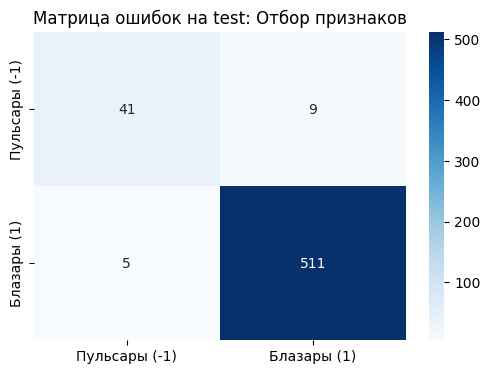

              precision    recall  f1-score   support

    Пульсары       0.89      0.82      0.85        50
     Блазары       0.98      0.99      0.99       516

    accuracy                           0.98       566
   macro avg       0.94      0.91      0.92       566
weighted avg       0.97      0.98      0.97       566

Пульсаров в test: 50


In [34]:
y_pred = test_predictions[best_name]
cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Пульсары (-1)', 'Блазары (1)'], yticklabels=['Пульсары (-1)', 'Блазары (1)'])
plt.title('Матрица ошибок на test: ' + best_name)
plt.show()

print(classification_report(y_test, y_pred, labels=[-1, 1],
                            target_names=['Пульсары', 'Блазары'], zero_division=0))
print('Пульсаров в test:', (y_test == -1).sum())


**ВЫВОД**

По F1 на validation выбран вариант с отбором признаков: Par26 и Par9.
На test: accuracy 0.9753, precision пульсаров 0.89, recall 0.82, F1 0.85.
Dummy даёт accuracy 0.9117, но не обнаруживает пульсары.

В этом разбиении PCA и oversampling не улучшили F1 относительно дерева
на исходных признаках. Это результат конкретных настроек, а не общий вывод
о бесполезности этих методов.

